<a href="https://colab.research.google.com/github/nasy-sr/artificial-intelligence-coursework-2024-genap/blob/main/02_uts_gender_classification_nb_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/AI_Class/gender_classification.csv')

In [ ]:
print("===== Informasi Dataset =====")
print(df.info())
print("\n===== Statistik Deskriptif =====")
print(df.describe())

print("\n===== Korelasi Antar Kolom =====")
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
print(correlation)

===== Informasi Dataset =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5001 entries, 0 to 5000
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   long_hair                  5001 non-null   int64  
 1   forehead_width_cm          5001 non-null   float64
 2   forehead_height_cm         5001 non-null   float64
 3   nose_wide                  5001 non-null   int64  
 4   nose_long                  5001 non-null   int64  
 5   lips_thin                  5001 non-null   int64  
 6   distance_nose_to_lip_long  5001 non-null   int64  
 7   gender                     5001 non-null   object 
dtypes: float64(2), int64(5), object(1)
memory usage: 312.7+ KB
None

===== Statistik Deskriptif =====
         long_hair  forehead_width_cm  forehead_height_cm    nose_wide  \
count  5001.000000        5001.000000         5001.000000  5001.000000   
mean      0.869626          13.181484            5.94

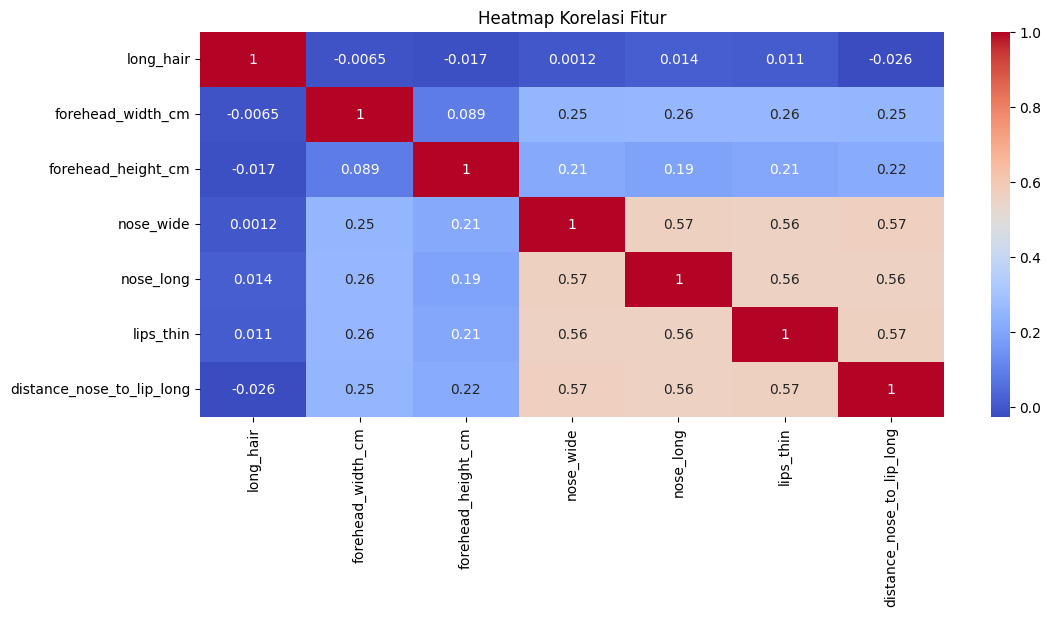

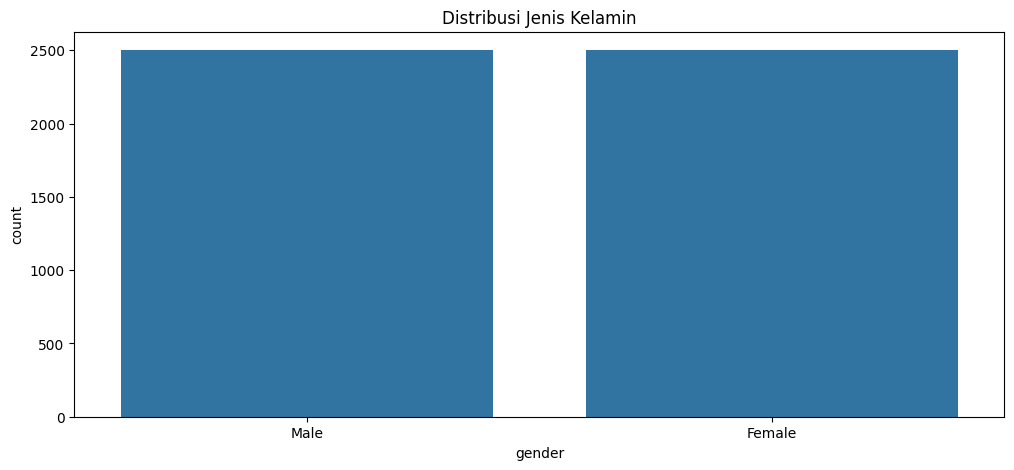

In [ ]:
plt.figure(figsize=(12, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title("Heatmap Korelasi Fitur")
plt.show()

plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='gender')
plt.title("Distribusi Jenis Kelamin")
plt.show()

In [ ]:
X = df.drop('gender', axis=1)
y = df['gender']

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.4, random_state=42)

In [ ]:
print(y_train)

[0 1 1 ... 0 0 0]


In [ ]:
print(X_train)

      long_hair  forehead_width_cm  forehead_height_cm  nose_wide  nose_long  \
1088          1               14.0                 6.0          0          0   
479           1               12.6                 6.4          1          1   
727           1               13.1                 6.5          1          1   
3783          0               12.6                 6.8          1          1   
976           1               11.9                 5.7          0          0   
...         ...                ...                 ...        ...        ...   
4426          1               13.0                 6.5          0          0   
466           1               13.1                 5.5          0          0   
3092          1               12.0                 5.9          0          0   
3772          1               12.8                 5.4          0          0   
860           1               11.4                 5.5          0          0   

      lips_thin  distance_nose_to_lip_l

In [ ]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

GaussianNB()

In [ ]:
nb_train_pred = nb_model.predict(X_train)
nb_test_pred = nb_model.predict(X_test)

print("\n===== Naive Bayes Classification =====")
print("Akurasi Training:", accuracy_score(y_train, nb_train_pred))
print("Akurasi Testing :", accuracy_score(y_test, nb_test_pred))
print("Classification Report (Test):\n", classification_report(y_test, nb_test_pred))


===== Naive Bayes Classification =====
Akurasi Training: 0.9703333333333334
Akurasi Testing : 0.9650174912543729
Classification Report (Test):
               precision    recall  f1-score   support

           0       0.97      0.96      0.96       984
           1       0.96      0.97      0.97      1017

    accuracy                           0.97      2001
   macro avg       0.97      0.96      0.97      2001
weighted avg       0.97      0.97      0.97      2001



In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

KNeighborsClassifier()

In [ ]:
knn_train_pred = knn_model.predict(X_train)
knn_test_pred = knn_model.predict(X_test)

print("\n===== K-Nearest Neighbors (KNN) Classification =====")
print("Akurasi Training:", accuracy_score(y_train, knn_train_pred))
print("Akurasi Testing :", accuracy_score(y_test, knn_test_pred))
print("Classification Report (Test):\n", classification_report(y_test, knn_test_pred))


===== K-Nearest Neighbors (KNN) Classification =====
Akurasi Training: 0.979
Akurasi Testing : 0.9620189905047476
Classification Report (Test):
               precision    recall  f1-score   support

           0       0.96      0.97      0.96       984
           1       0.97      0.96      0.96      1017

    accuracy                           0.96      2001
   macro avg       0.96      0.96      0.96      2001
weighted avg       0.96      0.96      0.96      2001



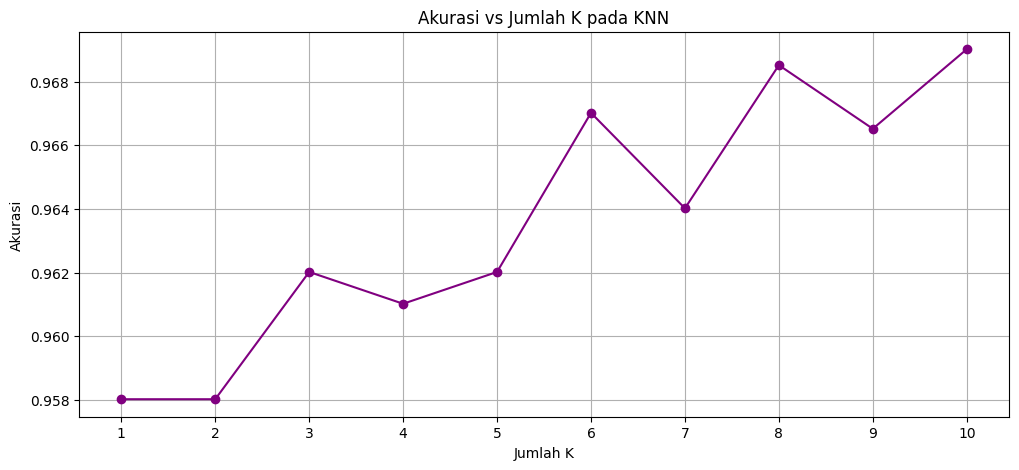

In [ ]:
accuracies = []
k_range = range(1, 11)
for k in k_range:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    accuracies.append(acc)

plt.figure(figsize=(12, 5))
plt.plot(k_range, accuracies, marker='o', linestyle='-', color='purple')
plt.title("Akurasi vs Jumlah K pada KNN")
plt.xlabel("Jumlah K")
plt.ylabel("Akurasi")
plt.xticks(k_range)
plt.grid(True)
plt.show()

In [ ]:
def predict_gender(features):
    input_data = np.array(features).reshape(1, -1)

    encoded_prediction = nb_model.predict(input_data)
    original_prediction = le.inverse_transform(encoded_prediction)
    return original_prediction[0]

example_features = [175.0, 65.0, 160.0, 25.0, 0.8, 18.0, 1]

predicted_gender = predict_gender(example_features)

print(f"Predicted Gender: {predicted_gender}")

Predicted Gender: Male


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


Confusion Matrix (Naive Bayes):


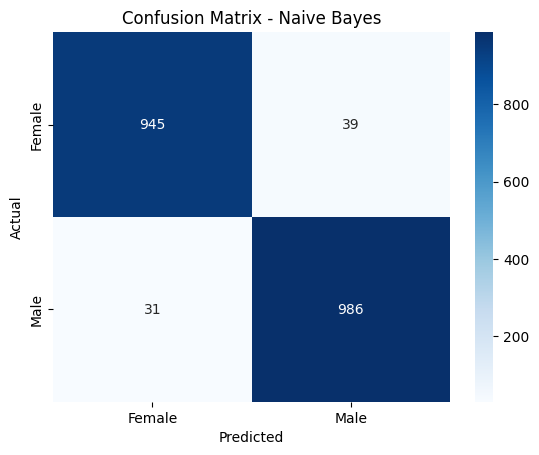

In [ ]:
print("Confusion Matrix (Naive Bayes):")
sns.heatmap(confusion_matrix(y_test, nb_test_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()

Confusion Matrix (KNN):


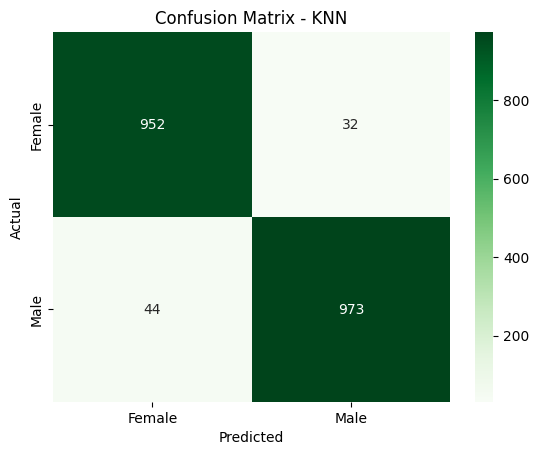

In [ ]:
print("Confusion Matrix (KNN):")
sns.heatmap(confusion_matrix(y_test, knn_test_pred), annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - KNN')
plt.show()
